# **Libraries**

In [1]:
# ---------------- Standard Libraries ----------------
import os
import pickle
from pathlib import Path
from datetime import datetime
import time
# ---------------- Data Handling ----------------
import numpy as np
import pandas as pd

# ---------------- Visualization ----------------
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.size': 9,
    'font.weight': 'bold',
    'font.family': 'serif'
})

# ---------------- Machine Learning (sklearn) ----------------
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score, average_precision_score
)
# ---------------- Deep Learning (PyTorch) ----------------
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import _LRScheduler
from torchsummary import summary


# ---------------- File Handling ----------------
import h5py
import hdf5storage

# ---------------- Utilities ----------------
from tqdm import tqdm
import joblib
import shap

# ---------------- Custom Function ----------------
def load_pickle(filepath):
    """
    Load a Python object from a pickle file.

    Parameters
    ----------
    filepath : str
        Path to the .pkl file.

    Returns
    -------
    obj : any
        The Python object stored in the pickle file.
    """
    with open(filepath, 'rb') as f:
        obj = pickle.load(f)
    return obj

def extract_pid(filename):
    part = filename.split('_')[0]          
    pid_full = part.split('-')[1]          
    pid = pid_full[5:]                     
    return pid

def group_gcs(y):
    if y in [3,4,5,6,7,8]:
        return 2 # Bad Neurological state
    elif y in [9,10,11,12]:
        return 1 # Moderate Neurological state
    elif y in [13,14,15]:
        return 0 # Good Neurological state
    else:
        return None 

def group_rass(y):
    if y in [-5, -4]:
        return 2 # Bad Neurological state
    elif y in [-3, -2]:
        return 1 # Moderate Neurological state
    elif y in [-1, 0]:
        return 0 # Good Neurological state
    else:
        return None 
        
def group_icans(y):
    if y in [0]:
        return 0 # Good Neurological state
    elif y in [1, 2]:
        return 1 # Moderate Neurological state
    elif y in [3, 4]:
        return 2 # Bad Neurological state
    else:
        return None 

def group_cams(x):
    if 0 <= x <= 1:
        return 0 # Good Neurological state
    elif 2 <= x <= 5:
        return 1 # Moderate Neurological state
    else:
        return 2 # Bad Neurological state

# **Load the Full Dataset**

In [2]:
# ------------------- CAMS - Dataset --------------------------
df_CAMS_metadata = pd.read_csv('/home/ayush/Desktop/CAM-S_dataset/CAMS_Training_Final_Metadata.csv')
df_CAMS_metadata["GroupedScore"] = df_CAMS_metadata["CAMS_SF"].apply(group_cams)
df_CAMS_metadata = df_CAMS_metadata.rename(columns={'CAMS_SF': 'RawScore'})
df_CAMS_metadata['Dataset'] = 'CAMS'
df_CAMS_metadata['TransformedScore'] = df_CAMS_metadata['RawScore']
df_CAMS_metadata = df_CAMS_metadata[['BDSPPatientID', 'Dataset', 'MorgothOutputFilename', 'RawScore', 'GroupedScore', 'TransformedScore']]

# ------------------- ICANS - Dataset --------------------------
df_ICANS_metadata = pd.read_csv('/home/ayush/Desktop/ICANS_dataset/ICANSTraining_Final_Metadata.csv')
df_ICANS_metadata["GroupedScore"] = df_ICANS_metadata["ICANS_raw"].apply(group_icans)
df_ICANS_metadata = df_ICANS_metadata.rename(columns={'StudyID':'BDSPPatientID',                                                      
                                                      'ICANS_raw': 'RawScore'})
df_ICANS_metadata['Dataset'] = 'ICANS'
df_ICANS_metadata['TransformedScore'] = df_ICANS_metadata['RawScore']
df_ICANS_metadata = df_ICANS_metadata[['BDSPPatientID', 'Dataset', 'MorgothOutputFilename', 'RawScore', 'GroupedScore', 'TransformedScore']]

# ------------------- GCS - Dataset --------------------------
df_GCS_metadata = pd.read_csv('/home/ayush/Desktop/MGB_GCS_EEGs/GCS_Filename_with_QC2.csv')
df_GCS_metadata['Filename'] = df_GCS_metadata['Filename'].astype(str) + '.csv'
df_GCS_metadata['GroupedScore'] = df_GCS_metadata['GCS_value'].apply(group_gcs)
df_GCS_metadata['BDSPPatientID'] = df_GCS_metadata['Filename'].apply(extract_pid)
df_GCS_metadata = df_GCS_metadata.rename(columns={'Filename': 'MorgothOutputFilename',
                                                  'GCS_value': 'RawScore'})
df_GCS_metadata['Dataset'] = 'GCS'
df_GCS_metadata['TransformedScore'] = 15-df_GCS_metadata['RawScore']
df_GCS_metadata = df_GCS_metadata[['BDSPPatientID', 'Dataset', 'MorgothOutputFilename', 'RawScore', 'GroupedScore', 'TransformedScore']]

# ------------------- RASS - Dataset --------------------------
df_RASS_metadata=pd.read_csv('/home/ayush/Desktop/MGB_RASS_EEGs/RASS_ALL_EEG_10min/RASS_files_updated_all.csv')
df_RASS_metadata['Filename'] = df_RASS_metadata['Filename'].str.rstrip("'") + '.csv'
df_RASS_metadata = df_RASS_metadata[
    ~df_RASS_metadata['RASS_value'].isin([1, 2, 3, 4])
]
df_RASS_metadata['GroupedScore'] = df_RASS_metadata['RASS_value'].apply(group_rass)
df_RASS_metadata['BDSPPatientID'] = df_RASS_metadata['Filename'].apply(extract_pid)
df_RASS_metadata['Dataset'] = 'RASS'
df_RASS_metadata = df_RASS_metadata.rename(columns={'Filename': 'MorgothOutputFilename',
                                                    'RASS_value': 'RawScore'})
df_RASS_metadata['TransformedScore'] = -df_RASS_metadata['RawScore']
df_RASS_metadata = df_RASS_metadata[['BDSPPatientID', 'Dataset', 'MorgothOutputFilename', 'RawScore', 'GroupedScore', 'TransformedScore']]

## ------------------ FULL DATASET (RASS- GCS - CAMS - ICANS) -------------------------
df_all_metadata = pd.concat(
    [df_RASS_metadata, df_GCS_metadata, df_CAMS_metadata, df_ICANS_metadata], # ],
    axis=0,
    ignore_index=True
)

df_all_metadata

,BDSPPatientID,Dataset,MorgothOutputFilename,RawScore,GroupedScore,TransformedScore
0,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg1.csv,-4,2,4
1,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg2.csv,-4,2,4
2,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg3.csv,-4,2,4
3,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg5.csv,-4,2,4
4,111189188,RASS,sub-S0001111189188_ses-2_eeg_10min_seg1.csv,-5,2,5
...,...,...,...,...,...,...
209761,1670,ICANS,1670_seg4_SourceStart_2019-10-20 09:06:30.csv,0,0,0
209762,1215,ICANS,1215_seg5_SourceStart_2020-01-23 12:05:37.csv,0,0,0
209763,1962,ICANS,1962_seg1_SourceStart_2019-05-02 16:41:32.csv,0,0,0
209764,1916,ICANS,1916_seg0_SourceStart_2019-05-05 14:34:40.csv,0,0,0


# **Split the dataset into train validation test using subject independent split**

In [3]:
from sklearn.model_selection import train_test_split

# CAMS = completely held-out Test cohort
cams_ids=set(df_all_metadata.loc[
    df_all_metadata['Dataset']=='CAMS','BDSPPatientID'
].unique())

df_test=df_all_metadata[
    df_all_metadata['Dataset']=='CAMS'
].copy().reset_index(drop=True)

# RASS + GCS + ICANS = Train/Val pool
df_trainval_pool=df_all_metadata[
    (df_all_metadata['Dataset']!='CAMS') &
    (~df_all_metadata['BDSPPatientID'].isin(cams_ids))
].copy()

# One row per patient
# Cannot stratify directly by Dataset because RASS/GCS patients can overlap
trainval_ids=df_trainval_pool['BDSPPatientID'].drop_duplicates().to_numpy()

# 80% Train / 20% Validation
train_ids,val_ids=train_test_split(
    trainval_ids,
    test_size=0.20,
    random_state=42
)

train_ids=set(train_ids)
val_ids=set(val_ids)
test_ids=cams_ids

df_train=df_trainval_pool[
    df_trainval_pool['BDSPPatientID'].isin(train_ids)
].copy().reset_index(drop=True)

df_val=df_trainval_pool[
    df_trainval_pool['BDSPPatientID'].isin(val_ids)
].copy().reset_index(drop=True)

# Assign splits to original dataframe
df_all_metadata['Split']='None'

df_all_metadata.loc[
    df_all_metadata['BDSPPatientID'].isin(train_ids),'Split'
]='Train'

df_all_metadata.loc[
    df_all_metadata['BDSPPatientID'].isin(val_ids),'Split'
]='Val'

df_all_metadata.loc[
    (df_all_metadata['Dataset']=='CAMS') &
    (df_all_metadata['BDSPPatientID'].isin(test_ids)),'Split'
]='Test'

print("="*60)
print("LEAVE-CAMS-COHORT-OUT")
print("="*60)

print(f"Train: {len(df_train):,} files | {df_train['BDSPPatientID'].nunique():,} subjects")
print(f"Val:   {len(df_val):,} files | {df_val['BDSPPatientID'].nunique():,} subjects")
print(f"Test:  {len(df_test):,} files | {df_test['BDSPPatientID'].nunique():,} subjects")

print("\nTRAIN subjects by dataset:")
print(df_train.groupby('Dataset')['BDSPPatientID'].nunique())

print("\nVAL subjects by dataset:")
print(df_val.groupby('Dataset')['BDSPPatientID'].nunique())

print("\nTEST subjects by dataset:")
print(df_test.groupby('Dataset')['BDSPPatientID'].nunique())

# Leakage checks
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert df_train['BDSPPatientID'].isin(test_ids).sum()==0
assert df_val['BDSPPatientID'].isin(test_ids).sum()==0
assert (df_test['Dataset']=='CAMS').all()

print("\nNo subject overlap between Train / Val / Test.")
print("CAMS is completely held out as the Test cohort.")

df_all_metadata

LEAVE-CAMS-COHORT-OUT
Train: 169,179 files | 6,422 subjects
Val:   40,061 files | 1,606 subjects
Test:  526 files | 523 subjects

TRAIN subjects by dataset:
Dataset
GCS      5687
ICANS     186
RASS     4952
Name: BDSPPatientID, dtype: int64

VAL subjects by dataset:
Dataset
GCS      1425
ICANS      51
RASS     1239
Name: BDSPPatientID, dtype: int64

TEST subjects by dataset:
Dataset
CAMS    523
Name: BDSPPatientID, dtype: int64

No subject overlap between Train / Val / Test.
CAMS is completely held out as the Test cohort.


,BDSPPatientID,Dataset,MorgothOutputFilename,RawScore,GroupedScore,TransformedScore,Split
0,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg1.csv,-4,2,4,Train
1,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg2.csv,-4,2,4,Train
2,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg3.csv,-4,2,4,Train
3,111189188,RASS,sub-S0001111189188_ses-12_eeg_10min_seg5.csv,-4,2,4,Train
4,111189188,RASS,sub-S0001111189188_ses-2_eeg_10min_seg1.csv,-5,2,5,Train
...,...,...,...,...,...,...,...
209761,1670,ICANS,1670_seg4_SourceStart_2019-10-20 09:06:30.csv,0,0,0,Val
209762,1215,ICANS,1215_seg5_SourceStart_2020-01-23 12:05:37.csv,0,0,0,Train
209763,1962,ICANS,1962_seg1_SourceStart_2019-05-02 16:41:32.csv,0,0,0,Train
209764,1916,ICANS,1916_seg0_SourceStart_2019-05-05 14:34:40.csv,0,0,0,Train


# **Feaure Engineering**

In [4]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm


def morgoth_output_file_location(data_group):
    base_paths = {
        "RASS": "/home/ayush/Desktop/MGB_RASS_EEGs/RASS_ALL_EEG_10min/MORGOTH_embeddings",
        "GCS": "/home/ayush/Desktop/MGB_GCS_EEGs/MORGOTH_GCS_Embeddings",
        "CAMS": "/home/ayush/Desktop/CAM-S_dataset/MORGOTH_Embeddings",
        "ICANS": "/home/ayush/Desktop/ICANS_dataset/Morgoth_embeddings_for_model"
    }

    root = base_paths[data_group]

    return {
        "SLOWING": os.path.join(root, "SLOWING"),
        "FOCGEN": os.path.join(root, "FOCGEN"),
        "IIIC": os.path.join(root, "IIIC"),
        "NM": os.path.join(root, "NM"),
        "BS": os.path.join(root, "BS"),
        "SLEEP": os.path.join(root, "SLEEP")
    }


def load_feature(path, filename):
    df = pd.read_csv(os.path.join(path, filename))
    if "pred_class" in df.columns:
        df = df.drop(columns=["pred_class"])
    return df.values


def morgoth_10minfea_matrix(data_frame):
    features = []
    file_names = []

    for row in tqdm(data_frame.itertuples(index=False), total=len(data_frame)):
        fname = row.MorgothOutputFilename
        dataset = row.Dataset

        paths = morgoth_output_file_location(dataset)

        sleep = load_feature(paths["SLEEP"], fname)
        nm = load_feature(paths["NM"], fname)
        bs = load_feature(paths["BS"], fname)

        focgen = load_feature(paths["FOCGEN"], fname)
        slowing = load_feature(paths["SLOWING"], fname)
        iiic = load_feature(paths["IIIC"], fname)

        subject_feature = np.concatenate(
            [sleep, nm, bs, focgen, slowing, iiic],
            axis=1
        )

        features.append(subject_feature)
        file_names.append(fname)

    X = np.stack(features, axis=0)

    Y_grouped = data_frame["GroupedScore"].to_numpy()
    Y_raw = data_frame["RawScore"].to_numpy()
    Y_raw_transformed = data_frame['TransformedScore'].to_numpy()

    dataset_names = data_frame["Dataset"].to_numpy()
    file_names = np.array(file_names)

    print("Grouped Label shape:", Y_grouped.shape)
    print("Raw Label shape:", Y_raw.shape)
    print("Raw Label transformed shape:", Y_raw_transformed.shape)
    print("Feature matrix shape:", X.shape)
    
    return X, Y_grouped, Y_raw, Y_raw_transformed, dataset_names, file_names

In [5]:
X_train_data, Ygrouped_train, Yraw_train, Yraw_transformed_train, train_dataset_names,trn_filenames = morgoth_10minfea_matrix(df_train)
X_val_data, Ygrouped_val, Yraw_val, Yraw_transformed_val, val_dataset_names, val_filenames = morgoth_10minfea_matrix(df_val)
X_tst_data, Ygrouped_tst, Yraw_tst, Yraw_transformed_tst, tst_dataset_names, tst_filenames = morgoth_10minfea_matrix(df_test)

100%|██████████████████████████████████| 169179/169179 [26:09<00:00, 107.82it/s]


Grouped Label shape: (169179,)
Raw Label shape: (169179,)
Raw Label transformed shape: (169179,)
Feature matrix shape: (169179, 591, 17)


100%|████████████████████████████████████| 40061/40061 [06:11<00:00, 107.90it/s]


Grouped Label shape: (40061,)
Raw Label shape: (40061,)
Raw Label transformed shape: (40061,)
Feature matrix shape: (40061, 591, 17)


100%|████████████████████████████████████████| 526/526 [00:04<00:00, 127.26it/s]

Grouped Label shape: (526,)
Raw Label shape: (526,)
Raw Label transformed shape: (526,)
Feature matrix shape: (526, 591, 17)


In [6]:
X_train_data_trch = torch.tensor(X_train_data, dtype=torch.float32)
X_val_data_trch   = torch.tensor(X_val_data, dtype=torch.float32)
X_tst_data_trch   = torch.tensor(X_tst_data, dtype=torch.float32)

Ygrouped_train_trch = torch.tensor(Ygrouped_train, dtype=torch.long)
Ygrouped_val_trch   = torch.tensor(Ygrouped_val, dtype=torch.long)
Ygrouped_tst_trch   = torch.tensor(Ygrouped_tst, dtype=torch.long)

Yraw_train_trch = torch.tensor(Yraw_train, dtype=torch.long)
Yraw_val_trch   = torch.tensor(Yraw_val, dtype=torch.long)
Yraw_tst_trch   = torch.tensor(Yraw_tst, dtype=torch.long)

train_dataset_names = np.array(train_dataset_names)
val_dataset_names   = np.array(val_dataset_names)
tst_dataset_names   = np.array(tst_dataset_names)

# **Get the Embeddings from the Frozen Triplet Model**

In [7]:
#-------------------------- ResNet-GAP only model -------------------------------------
import torch.nn.functional as F
class ResidualBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(out_ch)

        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm1d(out_ch)

        # If channels differ → use 1x1 conv for skip
        self.shortcut = nn.Sequential()
        if in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, kernel_size=1),
                nn.BatchNorm1d(out_ch)
            )

    def forward(self, x):
        identity = self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        return F.relu(out)

class MORGOTH_ResNet1D_onlyGAP(nn.Module):
    def __init__(self, num_features, filters=None, use_logit=True):
        super().__init__()
        self.use_logit = use_logit
        

        if filters is None:
            filters = [64, 128, 128, 256, 256]

        # Initial conv
        self.conv0 = nn.Conv1d(num_features, filters[0], kernel_size=7, padding=3)
        self.bn0 = nn.BatchNorm1d(filters[0])
        self.pool0 = nn.MaxPool1d(kernel_size=2)

        # ResNet blocks
        blocks = []
        in_ch = filters[0]
        for out_ch in filters:
            blocks.append(ResidualBlock1D(in_ch, out_ch))
            blocks.append(nn.MaxPool1d(kernel_size=2))
            in_ch = out_ch
        self.resnet_layers = nn.Sequential(*blocks)

        # GAP but DON'T squeeze yet
        self.gap = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(256, 40)
    def forward(self, x):
        if self.use_logit:
            eps = 1e-6
            x = torch.log((x + eps) / (1 - x + eps))

        x = x.permute(0, 2, 1)

        x = self.pool0(F.relu(self.bn0(self.conv0(x))))
        x = self.resnet_layers(x)

        # GAP: (B,C,1)
        x = self.gap(x).squeeze(-1)
        x = self.dropout(x)
        x = F.relu(x)
        x = self.fc(x)
        x = F.normalize(x, p=2, dim=1)
        return x

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# --------- LOAD MODEL ----------
model_trained = MORGOTH_ResNet1D_onlyGAP(num_features=17)
model_trained.load_state_dict(
    torch.load("/home/ayush/Desktop/NESI_review_material/Leave_one_Cohort_Out_Model/ModelCheckpoints/HoldoutCAM/ResNetGAP_HoldoutCAM_BestModel.pth",
               map_location=device,
               weights_only=True)
)
model_trained = model_trained.to(device)
model_trained.eval()

# --------- CREATE LOADERS ----------
train_ds_all = TensorDataset(X_train_data_trch)
val_ds_all   = TensorDataset(X_val_data_trch)
tst_ds_all   = TensorDataset(X_tst_data_trch)

train_dl_all = DataLoader(train_ds_all, batch_size=128, shuffle=False)
val_dl_all   = DataLoader(val_ds_all, batch_size=128, shuffle=False)
tst_dl_all   = DataLoader(tst_ds_all, batch_size=128, shuffle=False)

# --------- FUNCTION TO EXTRACT EMBEDDINGS ----------
def get_embeddings(model_trained, dataloader):
    all_embeddings = []

    with torch.no_grad():
        for (x,) in dataloader:
            x = x.to(device)
            emb = model_trained(x)
            all_embeddings.append(emb.cpu())

    return torch.cat(all_embeddings, dim=0)

# --------- GET EMBEDDINGS ----------
train_embeddings = get_embeddings(model_trained, train_dl_all)
val_embeddings   = get_embeddings(model_trained, val_dl_all)
tst_embeddings   = get_embeddings(model_trained, tst_dl_all)

print("Train embeddings shape:", train_embeddings.shape)
print("Val embeddings shape:", val_embeddings.shape)
print("Test embeddings shape:", tst_embeddings.shape)

Train embeddings shape: torch.Size([169179, 40])
Val embeddings shape: torch.Size([40061, 40])
Test embeddings shape: torch.Size([526, 40])


# **Pair-wise Global Score Preduction Model Training**

## **Pairwise data sampling**

In [9]:
import numpy as np
import random
from tqdm import tqdm


def create_pairs(
    embeddings,
    y_raw_transformed,
    y_grouped,
    dataset_names,
    mode="within_plus_global",
    k_pairs_per_anchor=4,
    hard_ratio=0.45,
    medium_ratio=0.30,
    easy_ratio=0.25,
    dataset_weights=None,
):

    N = len(embeddings)

    embeddings = np.array(embeddings)
    y_raw_transformed = np.array(y_raw_transformed)
    y_grouped = np.array(y_grouped)
    dataset_names = np.array(dataset_names)

    if dataset_weights is None:
        dataset_weights = {
            "RASS": 0.3,
            "GCS": 0.3,
            # "CAMS": 0.2,
            "ICANS": 0.4,
        }

    def sample_idx(cands):
        return random.choice(cands) if len(cands) > 0 else None

    # group indices
    dataset_to_indices = {}
    for i in range(N):
        d = dataset_names[i]
        dataset_to_indices.setdefault(d, []).append(i)

    pairs = []

    total_anchors = N // 10

    dataset_anchor_counts = {
        d: int(total_anchors * dataset_weights.get(d, 0.25))
        for d in dataset_to_indices.keys()
    }

    # =========================
    # DATASET LOOP (ONLY BAR)
    # =========================
    for dataset, indices in tqdm(dataset_to_indices.items(), desc="Creating Pairs"):

        anchor_count = dataset_anchor_counts.get(dataset, len(indices))
        anchor_indices = random.sample(indices, min(anchor_count, len(indices)))

        # NO inner tqdm here → prevents spam
        for i in anchor_indices:

            emb_i = embeddings[i]

            k = k_pairs_per_anchor

            n_hard = max(1, int(k * hard_ratio))
            n_med = max(1, int(k * medium_ratio))
            n_easy = max(1, k - n_hard - n_med)

            same_dataset_idx = indices
            yi = y_raw_transformed[i]

            # ---------------- HARD ----------------
            for _ in range(n_hard):
                candidates = [
                    j for j in same_dataset_idx
                    if abs(y_raw_transformed[j] - yi) <= 1e-3
                ]

                j = sample_idx(candidates)
                if j is None or j == i:
                    continue

                y = 1 if y_raw_transformed[i] > y_raw_transformed[j] else -1

                pairs.append((emb_i, embeddings[j], y, {
                    "type": "hard_within",
                    "dataset": dataset
                }))

            # ---------------- MEDIUM ----------------
            for _ in range(n_med):
                candidates = [
                    j for j in same_dataset_idx
                    if 0.5 < abs(y_raw_transformed[j] - yi) <= 3
                ]

                j = sample_idx(candidates)
                if j is None or j == i:
                    continue

                y = 1 if y_raw_transformed[i] > y_raw_transformed[j] else -1

                pairs.append((emb_i, embeddings[j], y, {
                    "type": "medium_within",
                    "dataset": dataset
                }))

            # ---------------- EASY ----------------
            for _ in range(n_easy):
                candidates = [
                    j for j in same_dataset_idx
                    if abs(y_raw_transformed[j] - yi) > 3
                ]

                j = sample_idx(candidates)
                if j is None or j == i:
                    continue

                y = 1 if y_raw_transformed[i] > y_raw_transformed[j] else -1

                pairs.append((emb_i, embeddings[j], y, {
                    "type": "easy_within",
                    "dataset": dataset
                }))

            # ---------------- CROSS ----------------
            if mode == "within_plus_global":

                cross_candidates = [
                    j for j in range(N)
                    if dataset_names[j] != dataset
                    and y_grouped[j] != y_grouped[i]
                ]

                for _ in range(max(1, k // 2)):

                    j = sample_idx(cross_candidates)
                    if j is None:
                        continue

                    y = 1 if y_grouped[i] > y_grouped[j] else -1

                    pairs.append((emb_i, embeddings[j], y, {
                        "type": "cross_global",
                        "dataset_i": dataset,
                        "dataset_j": dataset_names[j]
                    }))

    return pairs

In [10]:
import torch
from torch.utils.data import Dataset


class PairDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        emb_a, emb_b, y, meta = self.pairs[idx]

        emb_a = torch.tensor(emb_a, dtype=torch.float32)
        emb_b = torch.tensor(emb_b, dtype=torch.float32)
        y = torch.tensor(y, dtype=torch.float32)

        return emb_a, emb_b, y

## **Model building**

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class EEGScoringModel(nn.Module):
    def __init__(self, input_dim=40, hidden_dim=30, dropout=0.3):
        super(EEGScoringModel, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, 1)  # scalar badness score
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

## **Training code for the global score prediction model**

In [12]:
def pairwise_loss(score_a, score_b, y):
    """
    y = +1 if A worse than B else -1
    """
    return -torch.log(torch.sigmoid(y * (score_a - score_b)) + 1e-8).mean()

In [13]:
import torch


def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    epochs=100,
    save_path="./best_model.pth",
    patience=20
):

    best_val_loss = float("inf")
    patience_counter = 0

    model.to(device)

    for epoch in range(epochs):

        # =========================
        # TRAIN
        # =========================
        model.train()
        train_loss_total = 0.0

        for emb_a, emb_b, y in train_loader:

            emb_a = emb_a.to(device)
            emb_b = emb_b.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            score_a = model(emb_a)
            score_b = model(emb_b)

            loss = pairwise_loss(score_a, score_b, y)

            loss.backward()
            optimizer.step()

            train_loss_total += loss.item()

        train_loss = train_loss_total / len(train_loader)

        # =========================
        # VALIDATION
        # =========================
        model.eval()
        val_loss_total = 0.0

        with torch.no_grad():
            for emb_a, emb_b, y in val_loader:

                emb_a = emb_a.to(device)
                emb_b = emb_b.to(device)
                y = y.to(device)

                score_a = model(emb_a)
                score_b = model(emb_b)

                loss = pairwise_loss(score_a, score_b, y)

                val_loss_total += loss.item()

        val_loss = val_loss_total / len(val_loader)

        # =========================
        # LOGGING
        # =========================
        print(f"Epoch {epoch} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        # =========================
        # CHECKPOINT
        # =========================
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0

            torch.save({
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss
            }, save_path)

            print("✔ Saved best model")

        else:
            patience_counter += 1

        # =========================
        # EARLY STOPPING
        # =========================
        if patience_counter >= patience:
            print("⛔ Early stopping triggered")
            break

# **Implement the Global score prediction model**

## **Dataset prearation for pairwise training and dataloader creation**

In [14]:
train_pairs = create_pairs(
    embeddings=train_embeddings,
    y_raw_transformed=Yraw_transformed_train,
    y_grouped=Ygrouped_train,
    dataset_names=train_dataset_names,
    mode="within_plus_global"
)

val_pairs = create_pairs(
    embeddings=val_embeddings,
    y_raw_transformed=Yraw_transformed_val,
    y_grouped=Ygrouped_val,
    dataset_names=val_dataset_names,
    mode="within_plus_global"
)

train_dataset = PairDataset(train_pairs)
val_dataset = PairDataset(val_pairs)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)


Creating Pairs: 100%|█████████████████████████████| 3/3 [03:03<00:00, 61.28s/it]


## **Train the model**

In [15]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = EEGScoringModel()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    device=device,
    epochs=100,
    save_path="/home/ayush/Desktop/NESI_review_material/Leave_one_Cohort_Out_Model/ModelCheckpoints/HoldoutCAM/NESI_CAMS_Holdout_Best_model.pth",
    patience=20
)

Epoch 0 | Train Loss: 0.4747 | Val Loss: 0.4651
✔ Saved best model
Epoch 1 | Train Loss: 0.4580 | Val Loss: 0.4661
Epoch 2 | Train Loss: 0.4572 | Val Loss: 0.4664
Epoch 3 | Train Loss: 0.4560 | Val Loss: 0.4638
✔ Saved best model
Epoch 4 | Train Loss: 0.4552 | Val Loss: 0.4691
Epoch 5 | Train Loss: 0.4553 | Val Loss: 0.4657
Epoch 6 | Train Loss: 0.4543 | Val Loss: 0.4661
Epoch 7 | Train Loss: 0.4539 | Val Loss: 0.4636
✔ Saved best model
Epoch 8 | Train Loss: 0.4544 | Val Loss: 0.4668
Epoch 9 | Train Loss: 0.4552 | Val Loss: 0.4667
Epoch 10 | Train Loss: 0.4541 | Val Loss: 0.4650
Epoch 11 | Train Loss: 0.4536 | Val Loss: 0.4651
Epoch 12 | Train Loss: 0.4552 | Val Loss: 0.4630
✔ Saved best model
Epoch 13 | Train Loss: 0.4553 | Val Loss: 0.4631
Epoch 14 | Train Loss: 0.4542 | Val Loss: 0.4632
Epoch 15 | Train Loss: 0.4536 | Val Loss: 0.4636
Epoch 16 | Train Loss: 0.4539 | Val Loss: 0.4655
Epoch 17 | Train Loss: 0.4528 | Val Loss: 0.4636
Epoch 18 | Train Loss: 0.4535 | Val Loss: 0.4645
Epo

# **Load the trained model and get the EEG badness score**

In [16]:
def get_scores(model, embeddings, device="cuda", batch_size=256):
    model.eval()
    model.to(device)
    # ---------------- SAFE CONVERSION ----------------
    if not torch.is_tensor(embeddings):
        embeddings = torch.tensor(embeddings, dtype=torch.float32)
    else:
        embeddings = embeddings.detach().float()

    loader = torch.utils.data.DataLoader(
        embeddings,
        batch_size=batch_size,
        shuffle=False
    )

    all_scores = []
    with torch.no_grad():
        for x in loader:
            x = x.to(device)
            scores = model(x).squeeze(-1)
            all_scores.append(scores.cpu())

    return torch.cat(all_scores).numpy()

In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu"

checkpoint = torch.load(
    "/home/ayush/Desktop/NESI_review_material/Leave_one_Cohort_Out_Model/ModelCheckpoints/HoldoutCAM/NESI_CAMS_Holdout_Best_model.pth",
    map_location=device,
    weights_only=True
)

model_trained = EEGScoringModel()
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)

model.eval()

train_scores = get_scores(model, train_embeddings, device=device)
val_scores   = get_scores(model, val_embeddings, device=device)
test_scores  = get_scores(model, tst_embeddings, device=device)

# **Plot the EEG badness score**

In [22]:
import numpy as np
from scipy.stats import spearmanr


def compute_spearman_datasetwise(scores, y_transformed, dataset_names, split_name="Train"):

    scores = np.array(scores)
    y = np.array(y_transformed)
    datasets = np.array(dataset_names)

    unique_datasets = ["RASS", "GCS", "CAMS", "ICANS"]

    print(f"\n===== {split_name.upper()} SET SPEARMAN =====")

    results = {}

    for d in unique_datasets:
        mask = datasets == d

        if np.sum(mask) < 2:
            print(f"{d}: Not enough samples")
            results[d] = np.nan
            continue

        rho, _ = spearmanr(scores[mask], y[mask])
        results[d] = rho

        print(f"{d}: Spearman ρ = {rho:.4f}")

    return results


train_spearman_global = compute_spearman_datasetwise(
    train_scores,
    Yraw_transformed_train,
    train_dataset_names,
    split_name="Train"
)

# val_spearman_global = compute_spearman_datasetwise(
#     val_scores_global,
#     Yraw_transformed_val_global,
#     val_dataset_names_global,
#     split_name="Validation"
# )

tst_spearman_global = compute_spearman_datasetwise(
    test_scores,
    Yraw_transformed_tst,
    tst_dataset_names,
    split_name="Test"
)


===== TRAIN SET SPEARMAN =====
RASS: Spearman ρ = 0.7243
GCS: Spearman ρ = 0.7321
CAMS: Not enough samples
ICANS: Spearman ρ = 0.8917

===== TEST SET SPEARMAN =====
RASS: Not enough samples
GCS: Not enough samples
CAMS: Spearman ρ = 0.7782
ICANS: Not enough samples


In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_score_distributions_by_raw_train(
    predicted_scores,
    y_raw,
    dataset_names,
    title="Model Score Distribution by Raw Labels"
):
    # High DPI for crisp text and lines
    plt.rcParams['figure.dpi'] = 300
    sns.set_style("whitegrid")
    
    df = pd.DataFrame({
        "score": np.array(predicted_scores),
        "y_raw": np.array(y_raw),
        "dataset": np.array(dataset_names)
    })

    datasets = ["RASS", "GCS", "CAMS", "ICANS"]
    
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    axes = axes.flatten()

    for idx, d in enumerate(datasets):
        ax = axes[idx]
        sub = df[df["dataset"] == d].copy()

        if sub.empty:
            ax.set_title(f"{d} Dataset\n(No Data)", fontweight='bold')
            continue

        sub = sub.sort_values("y_raw")

        # Create the boxplot with strict black edge/line colors
        sns.boxplot(
            data=sub, 
            x="y_raw", 
            y="score", 
            hue="y_raw",          # Assigned hue to fix the FutureWarning
            legend=False,         # Hide legend as x-axis handles labels
            ax=ax,
            palette="pastel",
            showfliers=True,      # Show outliers as requested
            # Setting all line components to black
            boxprops={'edgecolor': 'black', 'linewidth': 1.5},
            whiskerprops={'color': 'black', 'linewidth': 1.5},
            capprops={'color': 'black', 'linewidth': 1.5},
            medianprops={'color': 'black', 'linewidth': 2},
            flierprops={'markerfacecolor': 'grey', 'markeredgecolor': 'black', 'markersize': 4}
        )

        # Bold formatting
        ax.set_title(f"{d} Dataset", fontweight='bold', fontsize=15, pad=15)
        ax.set_xlabel("Raw Score", fontweight='bold', fontsize=12)
        ax.set_ylabel("Predicted Badness Score", fontweight='bold', fontsize=12)
        
        # Adding a black border (spine) around the entire subplot
        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_visible(True)
            spine.set_linewidth(1.2)

        for label in (ax.get_xticklabels() + ax.get_yticklabels()):
            label.set_fontweight('bold')

    plt.suptitle(title, fontsize=20, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_score_distributions_by_raw_test(
    predicted_scores,
    y_raw,
    dataset_names,
    test_dataset="CAMS",
    title="Model Score Distribution by Raw Labels"
):
    plt.rcParams['figure.dpi']=300
    sns.set_style("whitegrid")

    df=pd.DataFrame({
        "score":np.array(predicted_scores),
        "y_raw":np.array(y_raw),
        "dataset":np.array(dataset_names)
    })

    sub=df[df["dataset"]==test_dataset].copy()

    if sub.empty:
        print(f"No {test_dataset} data found.")
        return

    sub=sub.sort_values("y_raw")

    fig,ax=plt.subplots(figsize=(8,6))

    sns.boxplot(
        data=sub,
        x="y_raw",
        y="score",
        hue="y_raw",
        legend=False,
        ax=ax,
        palette="pastel",
        showfliers=True,
        boxprops={'edgecolor':'black','linewidth':1.5},
        whiskerprops={'color':'black','linewidth':1.5},
        capprops={'color':'black','linewidth':1.5},
        medianprops={'color':'black','linewidth':2},
        flierprops={
            'markerfacecolor':'grey',
            'markeredgecolor':'black',
            'markersize':4
        }
    )

    ax.set_title(f"{test_dataset} Dataset",fontweight='bold',fontsize=15,pad=15)
    ax.set_xlabel("Raw Score",fontweight='bold',fontsize=12)
    ax.set_ylabel("Predicted Badness Score",fontweight='bold',fontsize=12)

    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_visible(True)
        spine.set_linewidth(1.2)

    for label in ax.get_xticklabels()+ax.get_yticklabels():
        label.set_fontweight('bold')

    plt.suptitle(title,fontsize=20,fontweight='bold',y=1.02)
    plt.tight_layout()
    plt.show()

## **Training set EEG badness score**

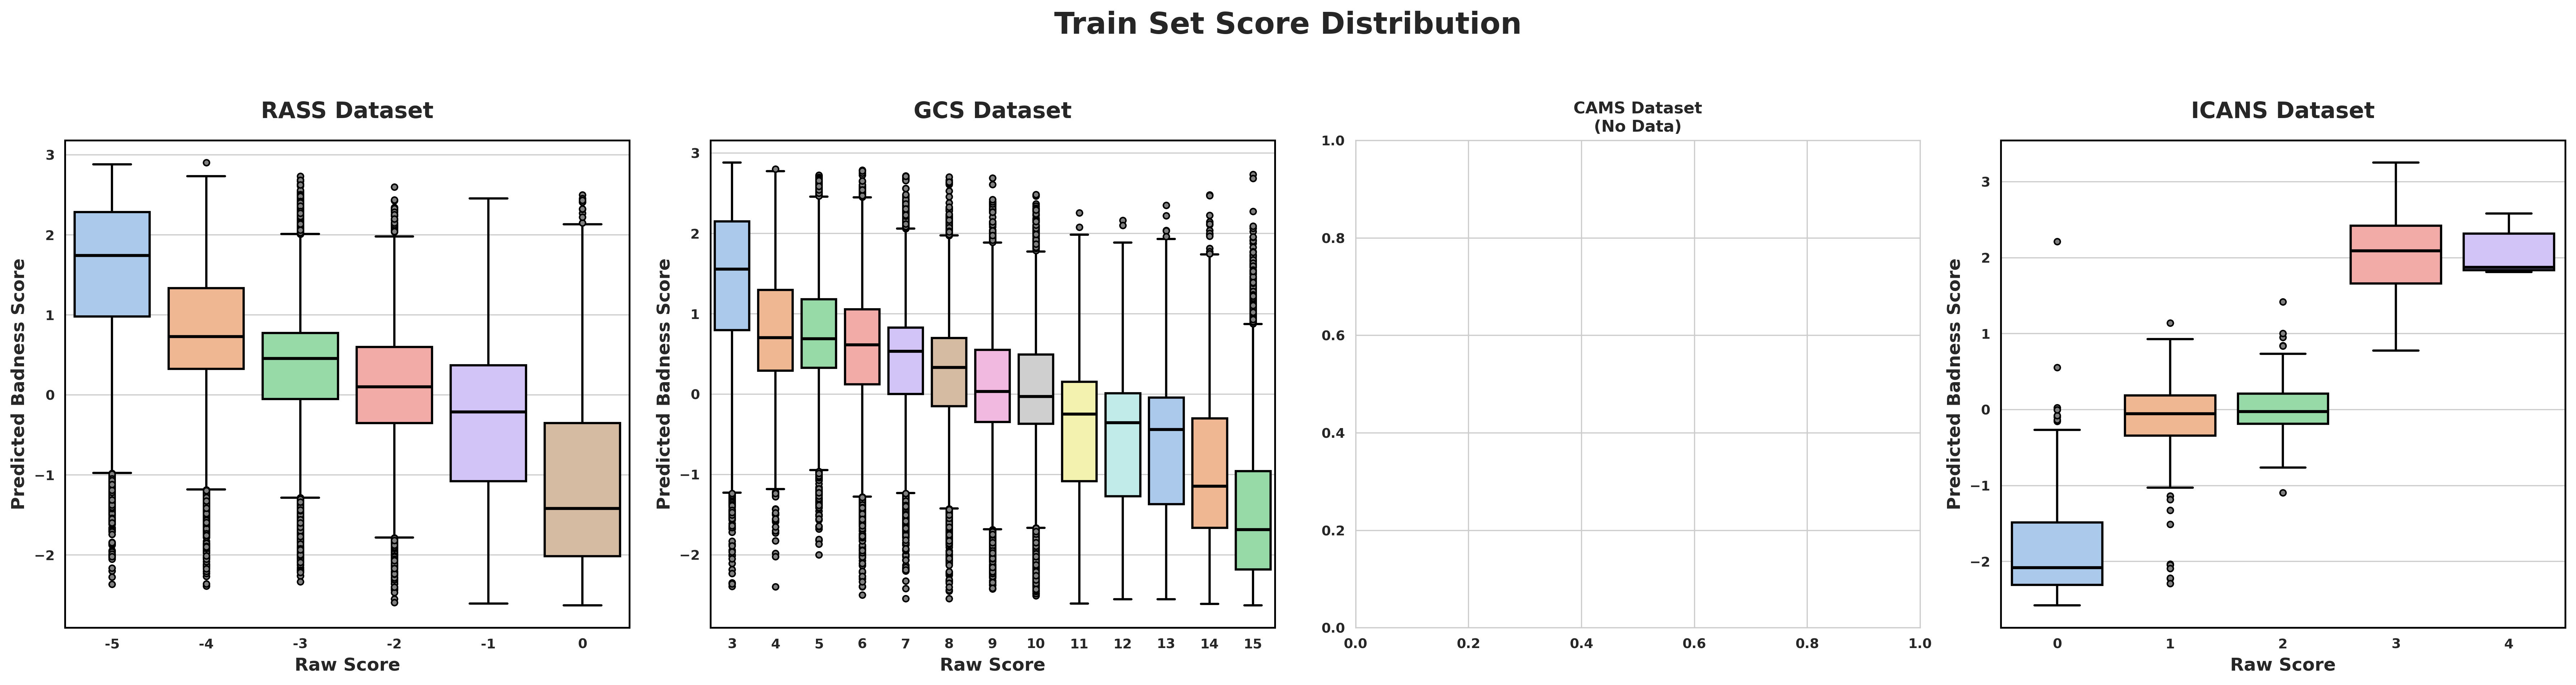

In [29]:
plot_score_distributions_by_raw_train(
    predicted_scores=train_scores,
    y_raw=Yraw_train,
    dataset_names=train_dataset_names,
    title="Train Set Score Distribution"
)

## **Validation set EEG badness score**

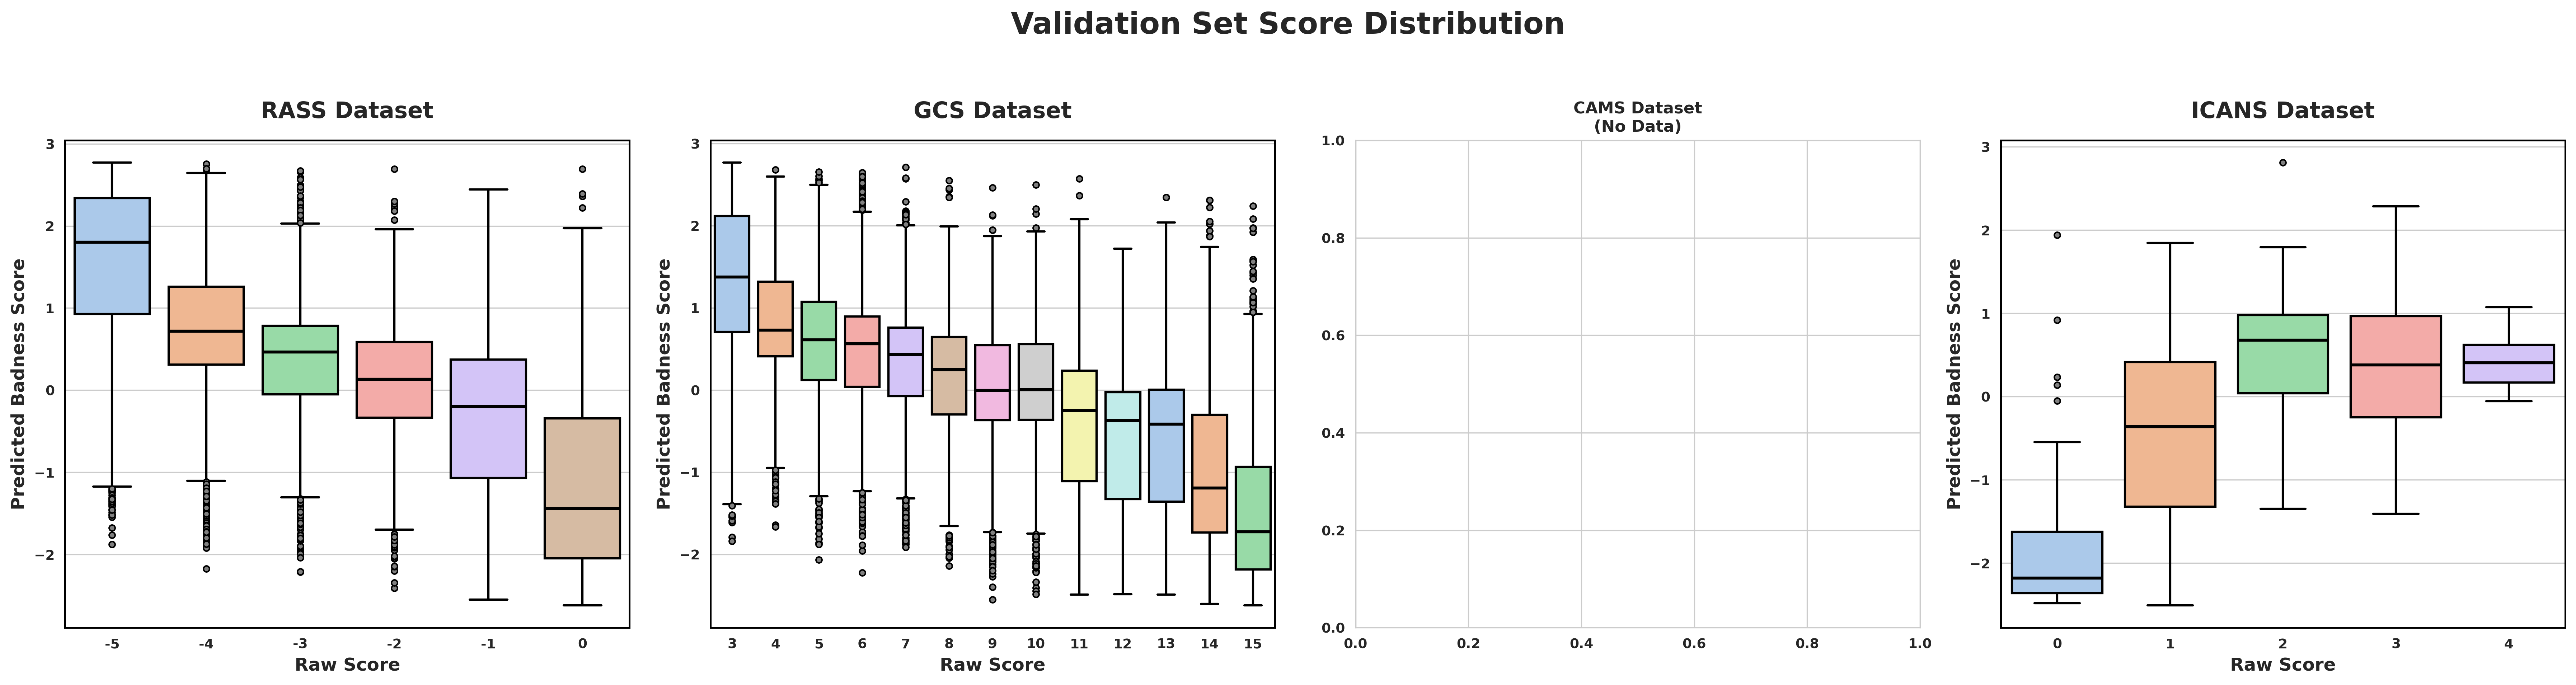

In [30]:
plot_score_distributions_by_raw_train(
    predicted_scores=val_scores,
    y_raw=Yraw_val,
    dataset_names=val_dataset_names,
    title="Validation Set Score Distribution"
)

## **Testing set EEG badness score**

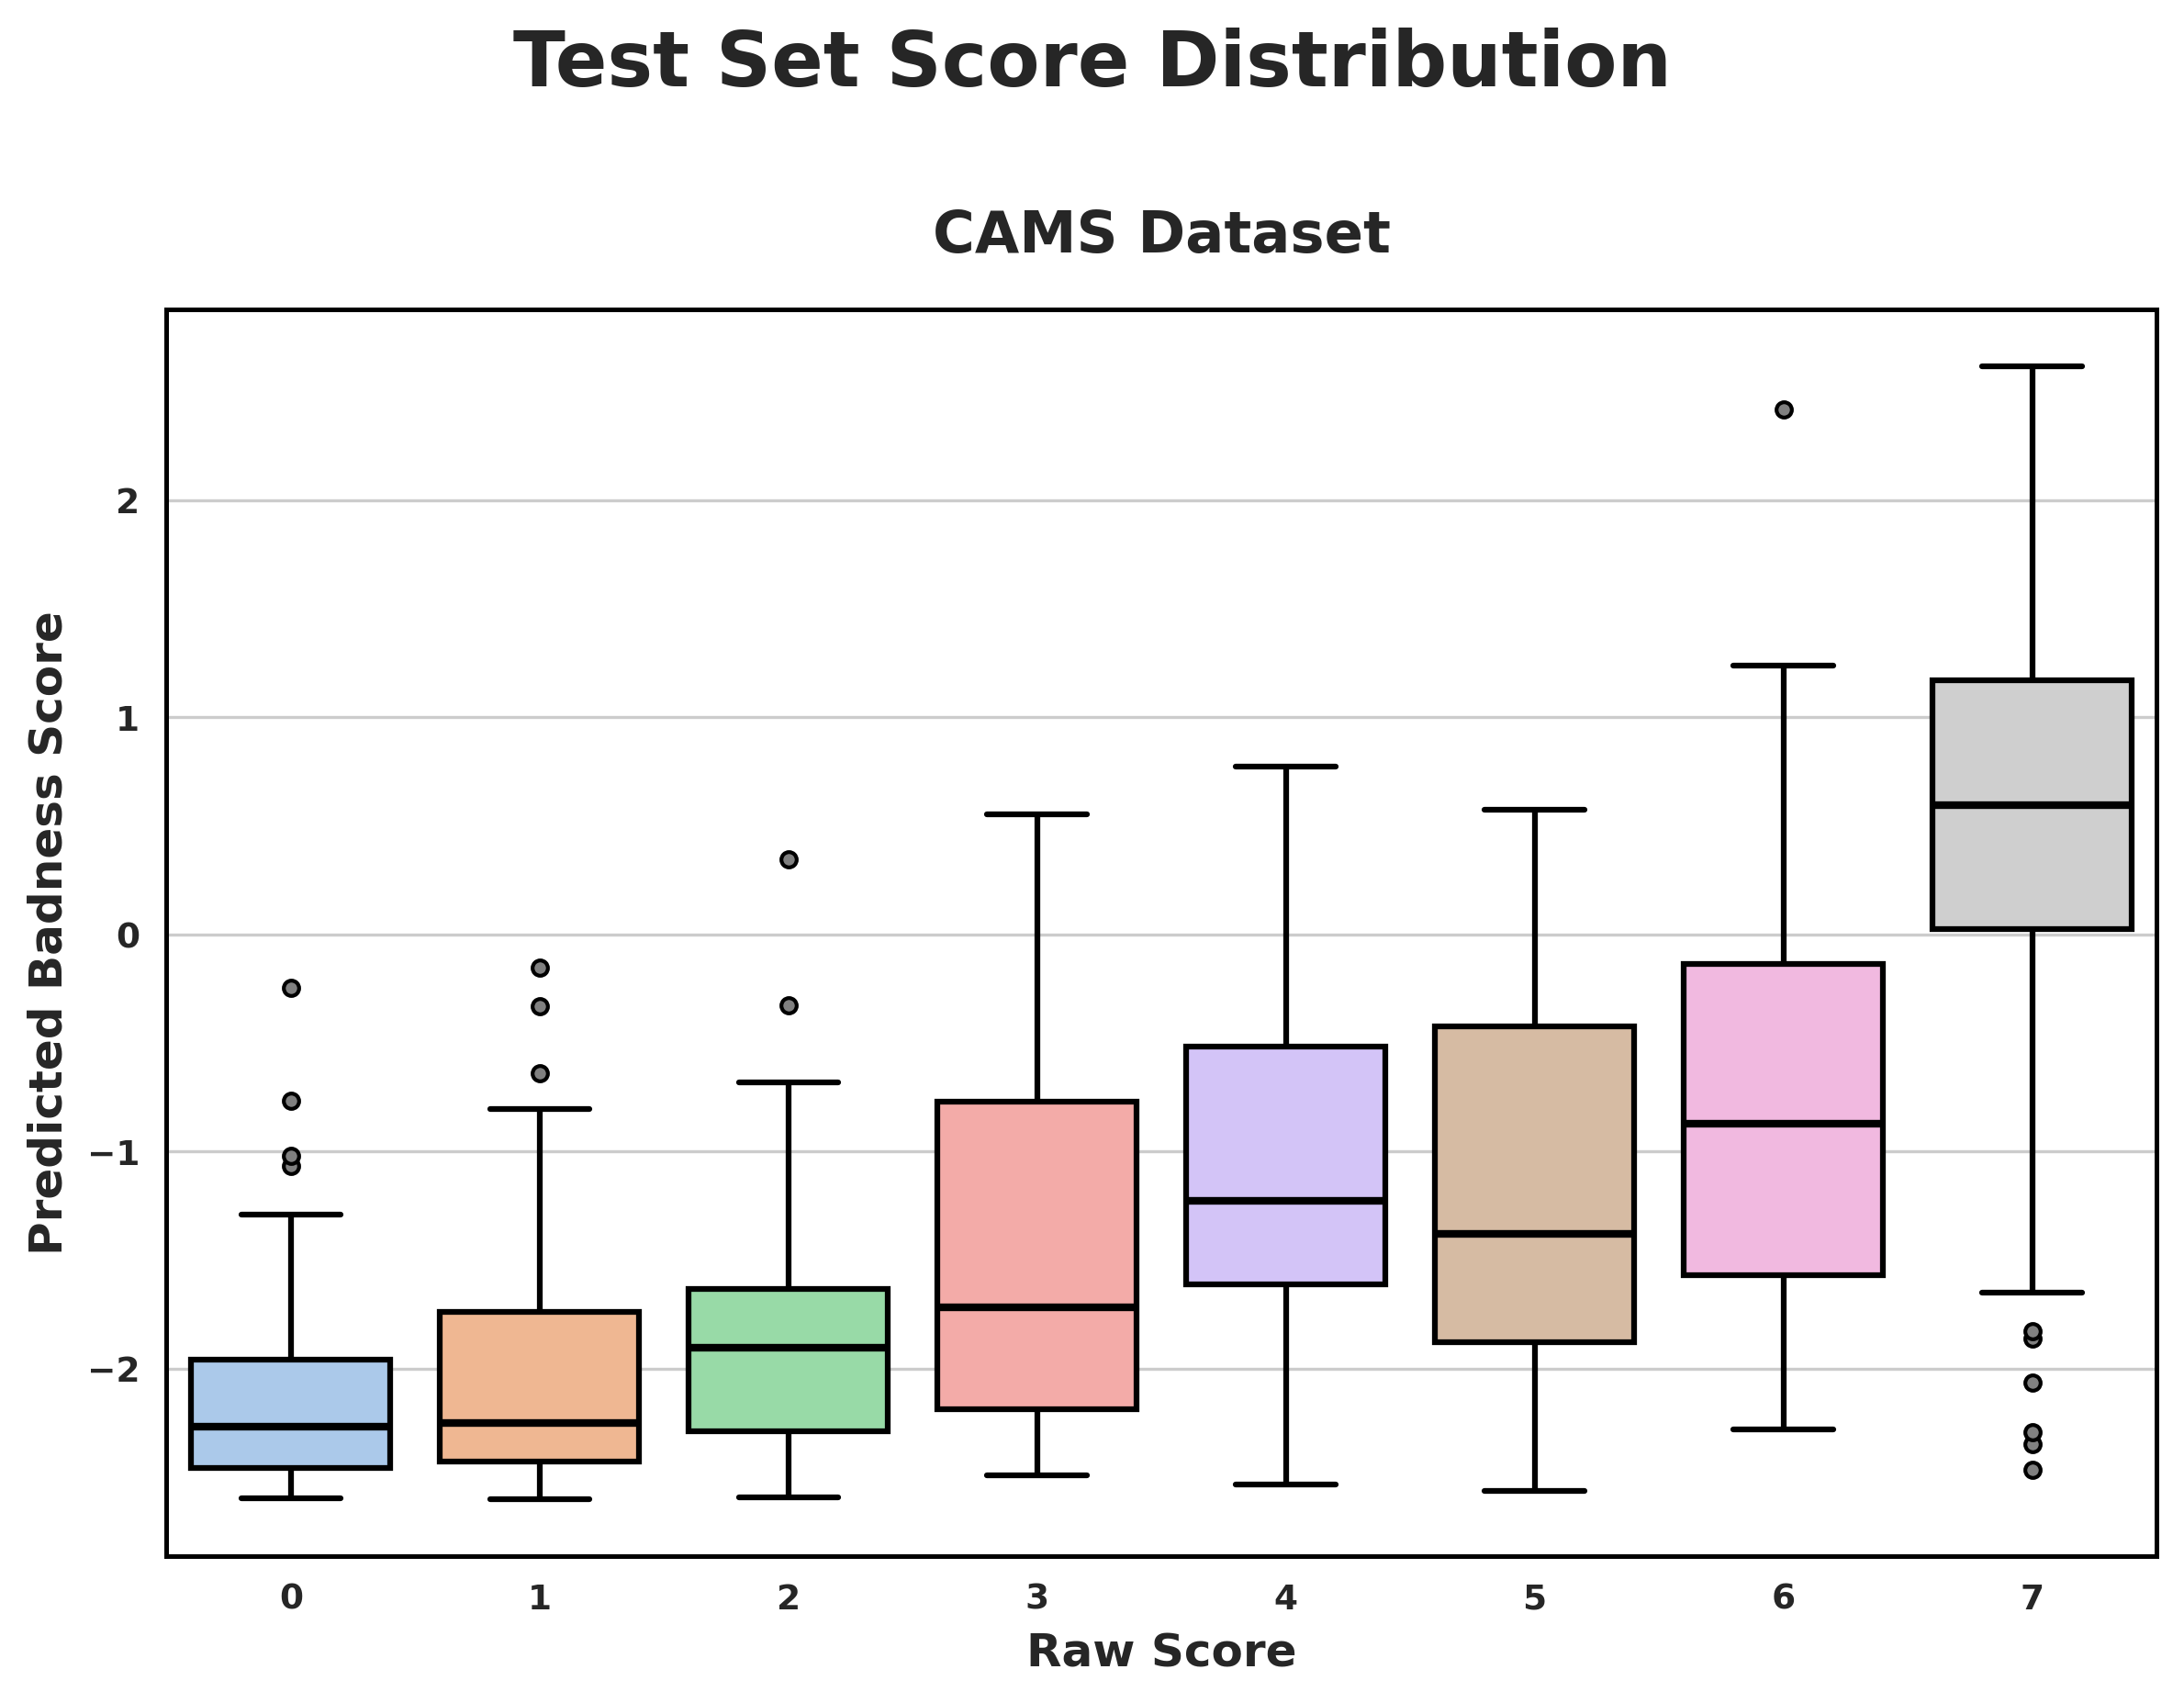

In [31]:
plot_score_distributions_by_raw_test(
    predicted_scores=test_scores,
    y_raw=Yraw_tst,
    dataset_names=tst_dataset_names,
    title="Test Set Score Distribution"
)

# **Spearman Correlation (ρ)**

In [32]:
import numpy as np
from scipy.stats import spearmanr

def compute_spearman_by_dataset(scores, y_transformed, dataset_names):

    scores = np.array(scores)
    y_transformed = np.array(y_transformed)
    dataset_names = np.array(dataset_names)

    datasets = ["RASS", "GCS", "CAMS", "ICANS"]

    results = {}

    for d in datasets:
        mask = dataset_names == d

        if np.sum(mask) < 2:
            results[d] = np.nan
            continue

        rho, _ = spearmanr(scores[mask], y_transformed[mask])
        results[d] = rho

    return results

import matplotlib.pyplot as plt

def plot_spearman_bar(results, title="Spearman Correlation"):

    names = list(results.keys())
    values = list(results.values())

    plt.figure(figsize=(8, 5))
    plt.bar(names, values)

    plt.axhline(0, linestyle="--")
    plt.ylim(-1, 1)

    plt.ylabel("Spearman ρ")
    plt.title(title)

    for i, v in enumerate(values):
        plt.text(i, v, f"{v:.2f}", ha='center', va='bottom')

    plt.show()

In [33]:
train_spearman = compute_spearman_by_dataset(
    train_scores,
    Yraw_transformed_train,
    train_dataset_names
)
val_spearman = compute_spearman_by_dataset(
    val_scores,
    Yraw_transformed_val,
    val_dataset_names
)
tst_spearman = compute_spearman_by_dataset(
    test_scores,
    Yraw_transformed_tst,
    tst_dataset_names
)

print(train_spearman)
print(val_spearman)
print(tst_spearman)

{'RASS': 0.7243180623693187, 'GCS': 0.7320608459204427, 'CAMS': nan, 'ICANS': 0.8917048660057192}
{'RASS': 0.7191577819810018, 'GCS': 0.702341322552099, 'CAMS': nan, 'ICANS': 0.6041025366409215}
{'RASS': nan, 'GCS': nan, 'CAMS': 0.7781885524398783, 'ICANS': nan}


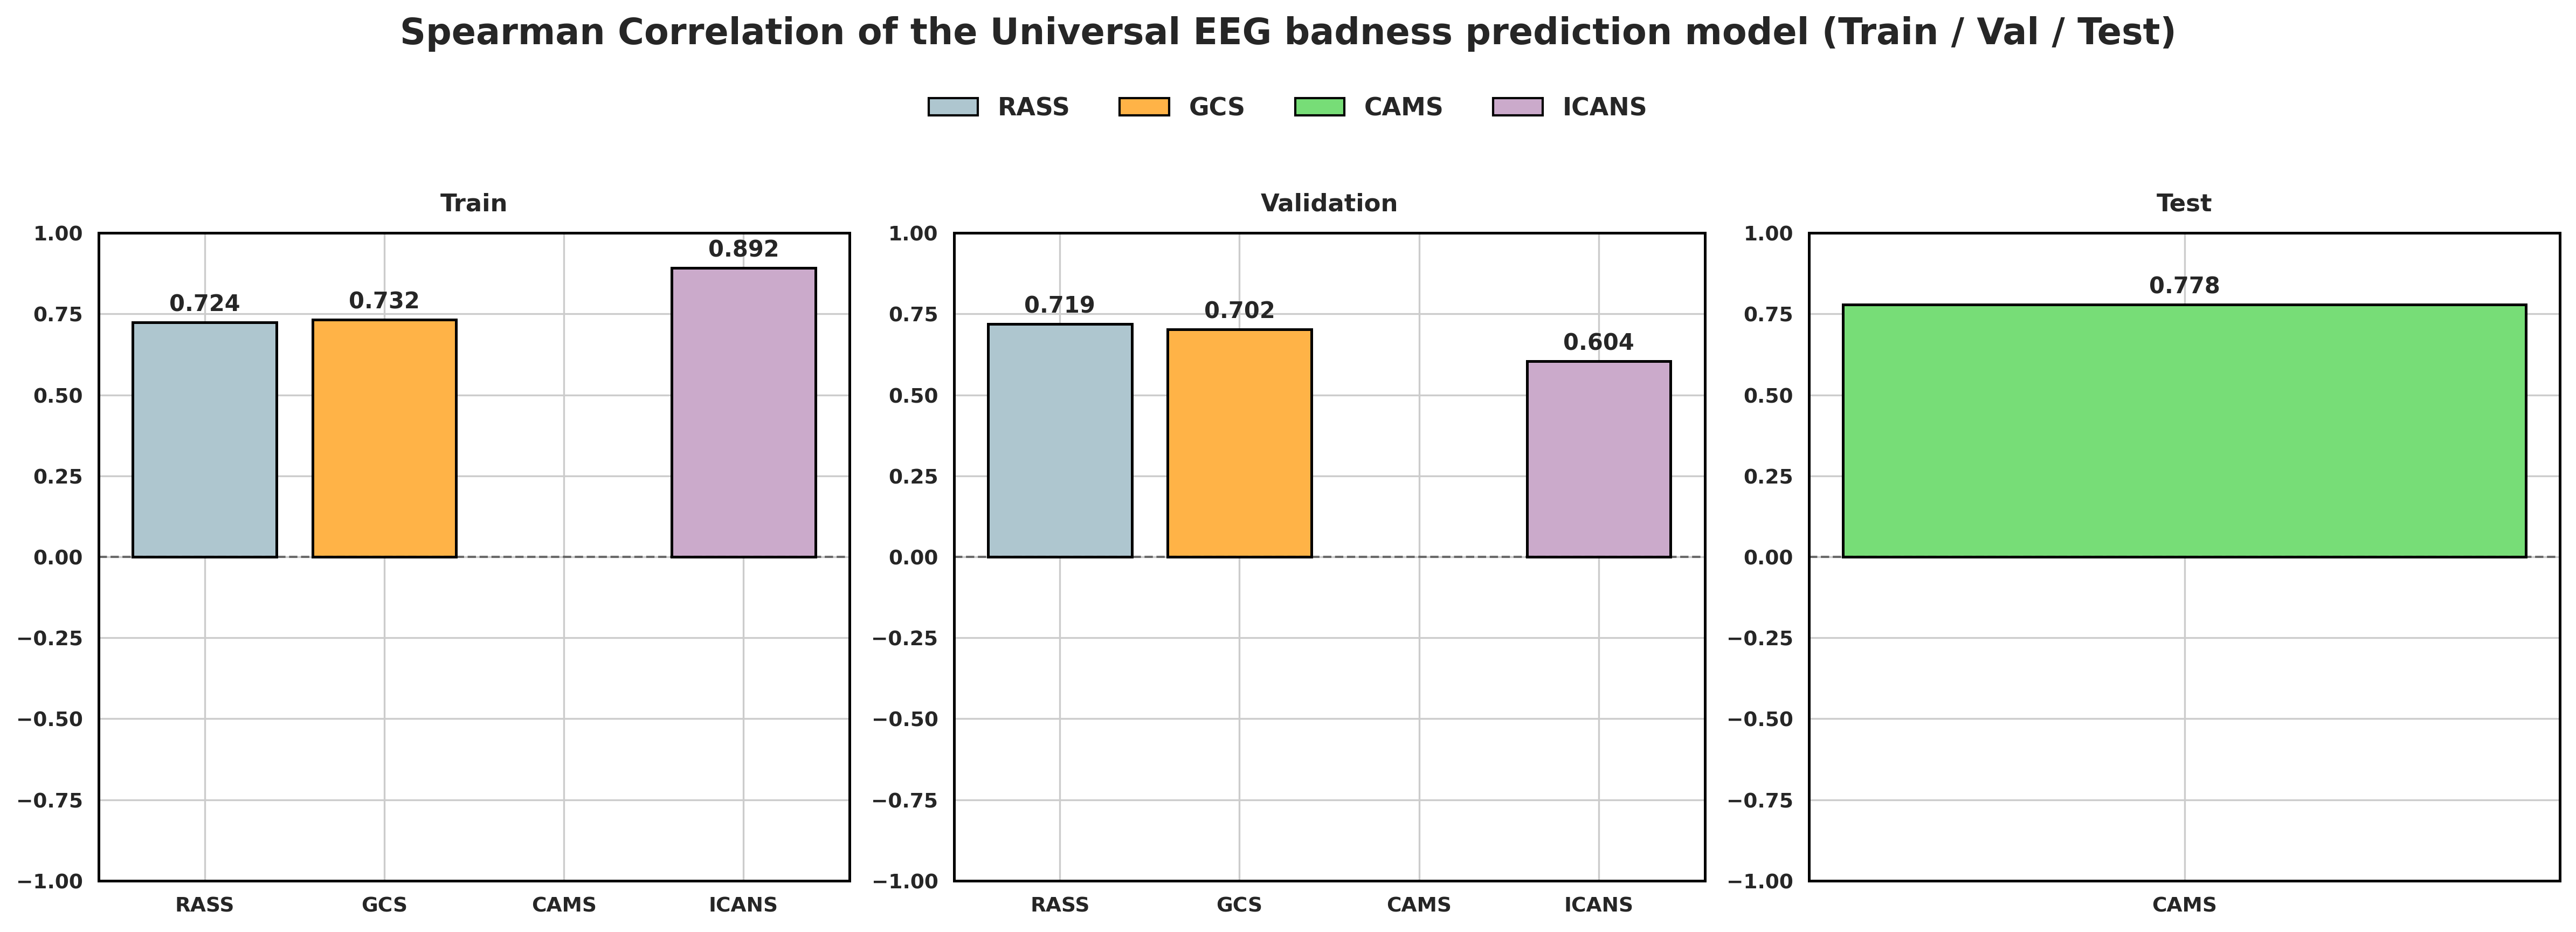

In [34]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_spearman_three(train_res, val_res, test_res,
                       title="Spearman Correlation of the Universal EEG badness prediction model (Train / Val / Test)"):

    datasets = ["RASS", "GCS", "CAMS", "ICANS"]

    colors = {
        "RASS": "#AEC6CF",
        "GCS":  "#FFB347",
        "CAMS": "#77DD77",
        "ICANS":"#CBAACB"
    }

    # Increased figure height slightly to accommodate legend/title spacing
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))

    splits = [
        ("Train", train_res),
        ("Validation", val_res),
        ("Test", test_res)
    ]

    for ax, (name, res) in zip(axes, splits):
        values = [res.get(d, float("nan")) for d in datasets]

        bars = ax.bar(
            datasets,
            values,
            color=[colors[d] for d in datasets],
            edgecolor="black",
            linewidth=1.2
        )

        # Set outer box (spines) to black
        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_linewidth(1.2)

        ax.set_title(name, pad=10, fontweight='bold')
        ax.set_ylim(-1, 1)
        ax.axhline(0, color='black', linestyle="--", linewidth=1, alpha=0.5)

        # Annotate values
        for i, v in enumerate(values):
            if v == v: # Check for NaN
                ax.text(i, v + 0.02 if v >= 0 else v - 0.05, 
                        f"{v:.3f}",
                        ha='center', va='bottom' if v >= 0 else 'top',
                        fontsize=10, fontweight='bold')

    # -------- GLOBAL LEGEND & TITLE FIX --------
    
    # Create legend handles using Patches (solid boxes)
    legend_handles = [Patch(facecolor=colors[d], edgecolor='black', label=d) for d in datasets]

    # Position Legend below the title but above the plots
    fig.legend(
        handles=legend_handles,
        labels=datasets,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.92), # Fine-tuned coordinates
        ncol=4,
        frameon=False,
        fontsize=11
    )

    fig.suptitle(title, fontsize=16, y=0.98, fontweight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.88])
    plt.show()


plot_spearman_three(train_spearman, val_spearman, tst_spearman)

# **Test HoldOut CAMS**